In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart


# 5. Специализированные методы: Croston и вариации

**Сквозной вопрос:** как разделить прогноз на «будет ли ненулевой спрос» и «если да, то сколько».

В этом ноутбуке:
- Croston (1972) — раздельные SES для размера спроса и интервала между продажами;
- смещение Croston и коррекция SBA (Syntetos–Boylan Approximation);
- TSB (Teunter–Syntetos–Babai) — вероятность продажи вместо интервала;
- ADIDA и IMAPA — временная агрегация, и как именно они устроены в `statsforecast`;
- сравнение со всеми бейзлайнами из ноутбука 4 по классам спроса.

In [1]:
import warnings

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsforecast import StatsForecast
from statsforecast.models import (
    ADIDA,
    IMAPA,
    TSB,
    CrostonClassic,
    CrostonOptimized,
    CrostonSBA,
    HistoricAverage,
    Naive,
    SeasonalNaive,
    SimpleExponentialSmoothing,
)

from utils import (
    demand_classes,
    evaluate_by_class,
    highlight_best,
    load_m5_ca1,
    metric_table,
    to_sf_format,
    train_test_split,
)

sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 4)

## 0. Данные

Те же M5 CA_1, горизонт H = 28 и разбиение, что в ноутбуке 4. Загрузка, разбиение, классификация
ADI/CV² и метрики вынесены в `utils.py` — общий модуль трёх ноутбуков про прерывистый спрос.
Классы считаем **только по обучению**, чтобы не подглядывать в тест.

In [2]:
H = 28

df_long = load_m5_ca1()
train, test = train_test_split(to_sf_format(df_long), h=H)
classes = demand_classes(train)

print(f"Товаров: {train['unique_id'].nunique()}, train: {len(train)}, test: {len(test)}")
classes['class'].value_counts()

Товаров: 3049, train: 5747365, test: 85372


class
intermittent    2191
lumpy            540
smooth           238
erratic           80
Name: count, dtype: int64

In [3]:
# Пример для иллюстраций: прерывистый товар, последние 200 дней обучения
example_id = classes.index[classes['class'] == 'intermittent'][0]
example_series = train.loc[train['unique_id'] == example_id, 'y'].values[-200:]
print(example_id, classes.loc[example_id, ['adi', 'cv2']].astype(float).round(2).to_dict())

FOODS_1_002_CA_1_validation {'adi': 3.01, 'cv2': 0.27}


## 1. Croston (1972)

**Идея:** прерывистый ряд — это два процесса. Запишем $y_t = x_t \cdot z_t$, где $x_t \in \{0, 1\}$ —
была ли продажа, $z_t$ — её размер. Вместо того чтобы сглаживать сам $y_t$ (SES тянет прогноз к нулю
после каждой серии нулей и подскакивает на каждой продаже), Croston сглаживает две величины,
**которые меняются только в моменты продаж**:
- $z$ — размер ненулевого спроса;
- $q$ — интервал (в периодах) с предыдущей продажи.

Если в момент $t$ была продажа:

$$\hat z_t = \alpha z_t + (1-\alpha)\hat z_{t-1}, \qquad \hat p_t = \alpha q_t + (1-\alpha)\hat p_{t-1},$$

иначе $\hat z_t = \hat z_{t-1}$, $\hat p_t = \hat p_{t-1}$. Прогноз — средний спрос за период:

$$\hat y_{t+h} = \frac{\hat z_t}{\hat p_t} \quad \text{для всех } h.$$

Пример: в среднем продаём 6 штук раз в 3 дня → прогноз 2 шт./день. Прогноз плоский по горизонту и
**не меняется между продажами** — только в дни продаж.

**В `statsforecast`:**
- `CrostonClassic` — $\alpha = 0.1$ для обеих величин, инициализация первыми значениями
  ($\hat z$ = первая продажа, $\hat p$ = номер периода первой продажи);
- `CrostonOptimized` — $\alpha$ подбирается **отдельно** для $\hat z$ и для $\hat p$ минимизацией
  in-sample MSE на отрезке $[0.1, 0.3]$;
- если продаж в истории нет, все модели семейства возвращают 0.

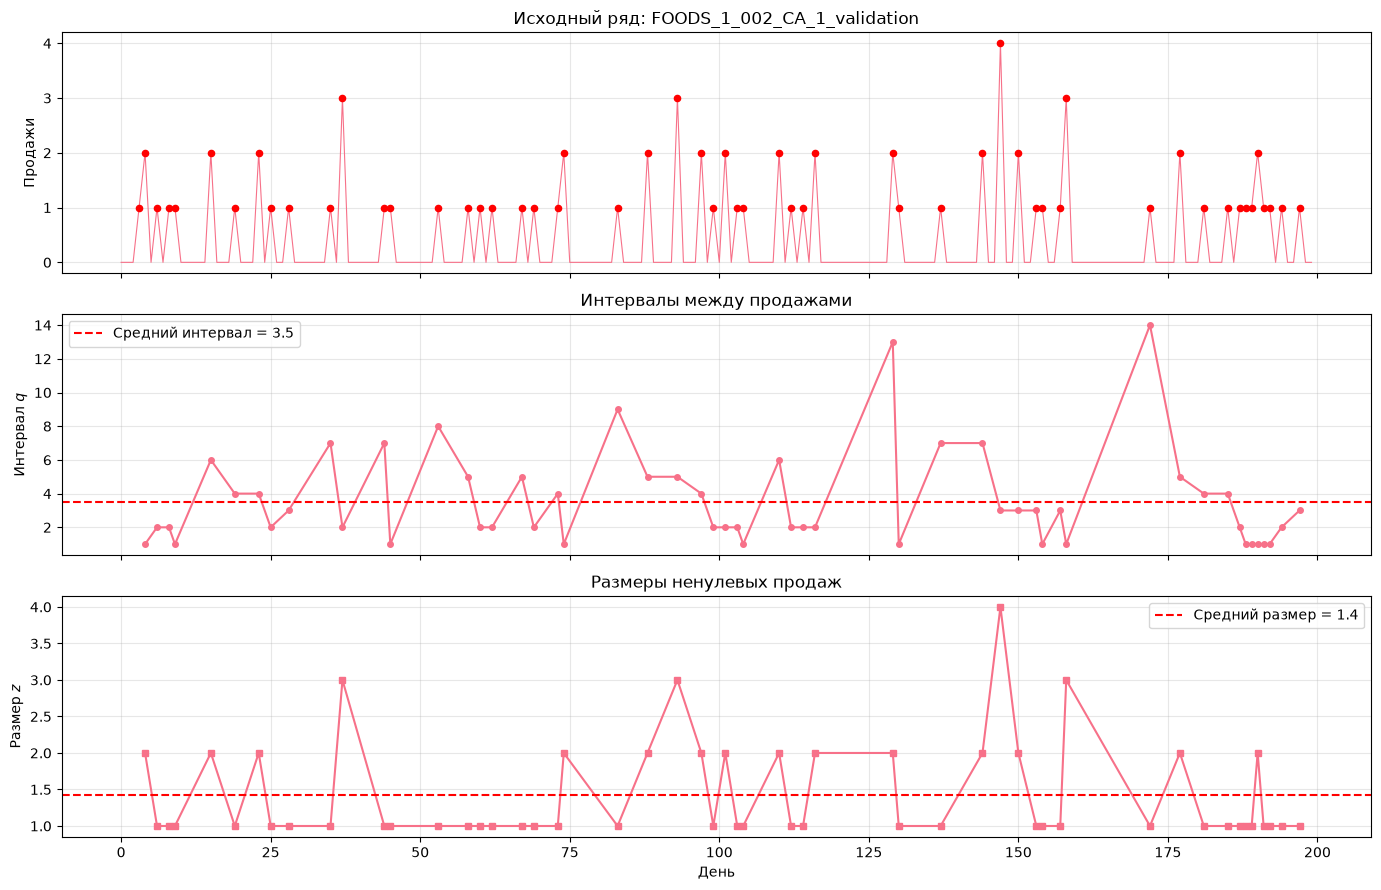

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

nonzero_idx = np.flatnonzero(example_series)
intervals = np.diff(nonzero_idx)
sizes = example_series[nonzero_idx[1:]]

axes[0].plot(example_series, linewidth=0.8)
axes[0].scatter(nonzero_idx, example_series[nonzero_idx], color='red', s=20, zorder=5)
axes[0].set_ylabel('Продажи')
axes[0].set_title(f'Исходный ряд: {example_id}')

axes[1].plot(nonzero_idx[1:], intervals, 'o-', markersize=4)
axes[1].axhline(intervals.mean(), color='red', linestyle='--', label=f'Средний интервал = {intervals.mean():.1f}')
axes[1].set_ylabel('Интервал $q$')
axes[1].set_title('Интервалы между продажами')
axes[1].legend()

axes[2].plot(nonzero_idx[1:], sizes, 's-', markersize=4)
axes[2].axhline(sizes.mean(), color='red', linestyle='--', label=f'Средний размер = {sizes.mean():.1f}')
axes[2].set_ylabel('Размер $z$')
axes[2].set_title('Размеры ненулевых продаж')
axes[2].set_xlabel('День')
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Croston руками: возвращаем прогноз на каждый момент, чтобы увидеть, как он «стоит» между продажами.
Последнее значение совпадает с `CrostonClassic` из `statsforecast`.

Руками: 0.4613, statsforecast: 0.4613


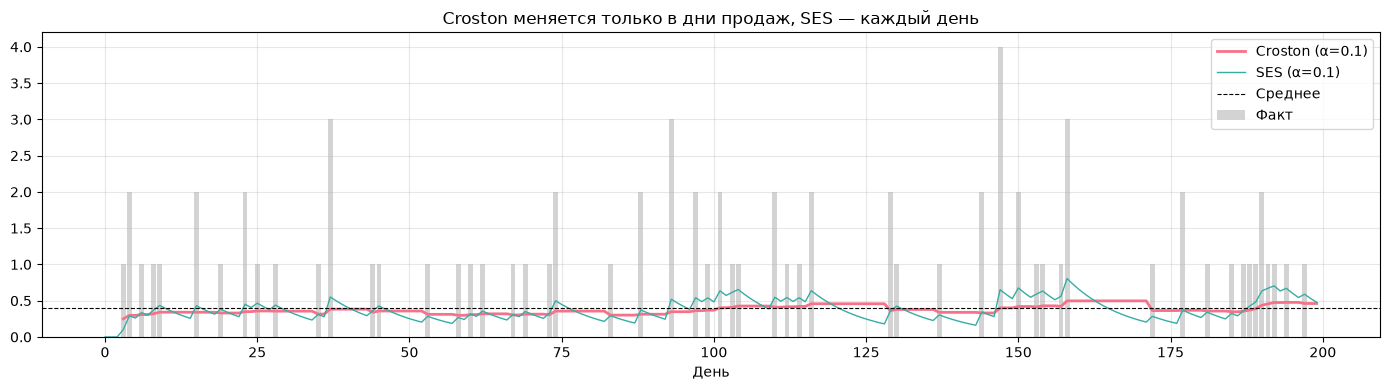

In [5]:
def croston_path(y, alpha=0.1):
    """Прогноз Croston после каждого наблюдения (NaN до первой продажи)."""
    nz = np.flatnonzero(y)
    gaps = np.diff(nz + 1, prepend=0)  # интервал до первой продажи считаем от начала ряда
    z_hat, p_hat = float(y[nz[0]]), float(gaps[0])
    path = np.full(len(y), np.nan)
    path[nz[0]:] = z_hat / p_hat
    for t, q in zip(nz[1:], gaps[1:]):
        z_hat = alpha * y[t] + (1 - alpha) * z_hat
        p_hat = alpha * q + (1 - alpha) * p_hat
        path[t:] = z_hat / p_hat
    return path


def ses_path(y, alpha=0.1):
    path = np.empty(len(y))
    level = y[0]
    for t, v in enumerate(y):
        level = alpha * v + (1 - alpha) * level if t else level
        path[t] = level
    return path


croston_manual = croston_path(example_series)
croston_lib = CrostonClassic().forecast(y=example_series.astype(float), h=1)['mean'][0]
print(f"Руками: {croston_manual[-1]:.4f}, statsforecast: {croston_lib:.4f}")

plt.figure(figsize=(14, 4))
plt.bar(range(len(example_series)), example_series, color='lightgray', label='Факт')
plt.plot(croston_manual, color='C0', linewidth=2, label='Croston (α=0.1)')
plt.plot(ses_path(example_series.astype(float)), color='C3', linewidth=1, label='SES (α=0.1)')
plt.axhline(example_series.mean(), color='black', linestyle='--', linewidth=0.8, label='Среднее')
plt.title('Croston меняется только в дни продаж, SES — каждый день')
plt.xlabel('День')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Смещение Croston и SBA

Croston **завышает** прогноз. $\hat z$ и $\hat p$ по отдельности несмещённые, но прогноз — их отношение,
а $1/p$ — выпуклая функция. По неравенству Йенсена
$\mathbb E\left[\frac{1}{\hat p}\right] > \frac{1}{\mathbb E[\hat p]}$, поэтому
$\mathbb E\left[\frac{\hat z}{\hat p}\right] > \frac{\mu_z}{\mu_p}$.

Смещение растёт вместе с разбросом $\hat p$, а разброс SES-оценки растёт с $\alpha$ (меньше
наблюдений усредняется). Значит, **чем больше α, тем сильнее перепрогноз**.

Syntetos и Boylan (2005) получили приближённую поправку:

$$\hat y^{SBA} = \left(1 - \frac{\alpha}{2}\right)\frac{\hat z}{\hat p}.$$

В `statsforecast` `CrostonSBA` — это `CrostonClassic` с $\alpha = 0.1$, умноженный на $0.95$.

Проверим на симуляции. Один ряд ничего не докажет — смещение это свойство среднего по многим рядам.
Сгенерируем 2000 рядов с известным уровнем спроса: продажа с вероятностью 0.2, размер $1 + \text{Poisson}(4)$,
то есть истинный средний спрос $0.2 \cdot 5 = 1$.

In [6]:
rng = np.random.default_rng(42)
n_series, n_periods = 2000, 400
prob, size_mean = 0.2, 5
true_rate = prob * size_mean

synthetic = np.where(
    rng.random((n_series, n_periods)) < prob,
    1 + rng.poisson(size_mean - 1, (n_series, n_periods)),
    0,
).astype(float)

rows = []
for alpha in [0.05, 0.1, 0.2, 0.3, 0.5]:
    croston = np.array([croston_path(y, alpha)[-1] for y in synthetic])
    for name, fc in [('Croston', croston), ('SBA', (1 - alpha / 2) * croston)]:
        rows.append({'α': alpha, 'Метод': name, 'Смещение, %': 100 * (fc.mean() / true_rate - 1)})

bias_sim = pd.DataFrame(rows).pivot(index='α', columns='Метод', values='Смещение, %')
bias_sim.round(1)

Метод,Croston,SBA
α,,
0.05,2.3,-0.3
0.10,4.7,-0.6
0.20,9.8,-1.1
0.30,15.5,-1.8
0.50,29.2,-3.1


Смещение Croston растёт с α: доли процента при α = 0.05 и десятки процентов при α = 0.5.
SBA убирает почти всё; небольшое недопрогнозирование при больших α — плата за то, что поправка приближённая.

## 3. TSB (Teunter–Syntetos–Babai, 2011)

У Croston есть вторая проблема: между продажами прогноз **заморожен**. Если товар сняли с продажи,
Croston продолжит прогнозировать прежний уровень сколько угодно долго.

TSB заменяет интервал на **вероятность продажи** $\hat p_t$ и обновляет её **каждый период**:

$$\hat p_t = \alpha_p \cdot \mathbb 1\{y_t > 0\} + (1 - \alpha_p)\,\hat p_{t-1},$$
$$\hat z_t = \begin{cases} \alpha_d z_t + (1-\alpha_d)\hat z_{t-1}, & y_t > 0 \\ \hat z_{t-1}, & y_t = 0 \end{cases}$$
$$\hat y_{t+h} = \hat p_t \cdot \hat z_t.$$

- Каждый ноль уменьшает $\hat p$ → прогноз плавно снижается во время простоя (устаревание товара).
- Произведение, а не отношение → нет смещения из-за Йенсена, коррекция как у SBA не нужна.
- Две отдельные константы: $\alpha_p$ отвечает за скорость реакции на изменение частоты продаж.

**В `statsforecast`:** `TSB(alpha_d, alpha_p)` — оба параметра задаются вручную, подбора нет.
Инициализация: $\hat p_0 = \mathbb 1\{y_0 > 0\}$, $\hat z$ — первая продажа.

Пример: товар продавался 200 дней, потом продажи прекратились.

TSB руками: 0.0000, statsforecast: 0.0000


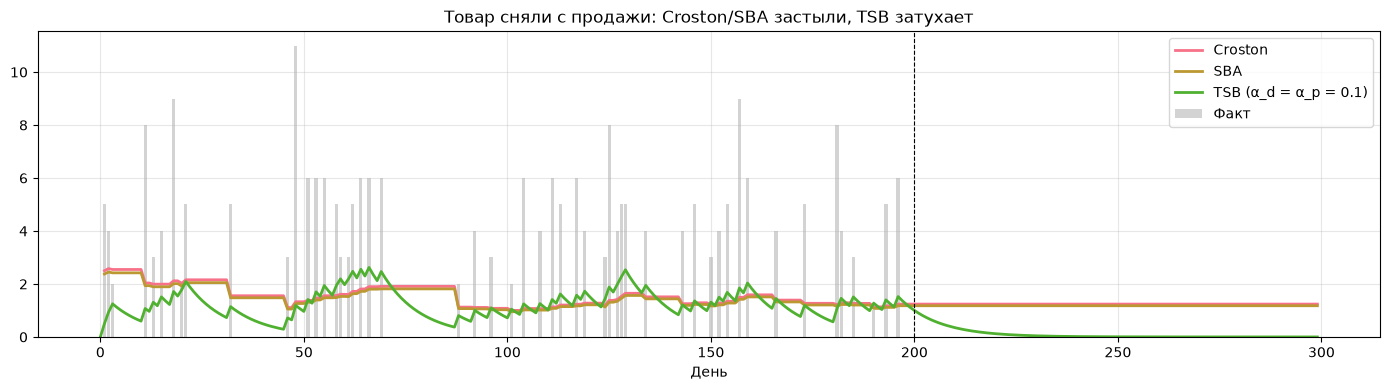

In [7]:
def tsb_path(y, alpha_d=0.1, alpha_p=0.1):
    """Прогноз TSB после каждого наблюдения."""
    nz = np.flatnonzero(y)
    z_hat, p_hat = float(y[nz[0]]), float(y[0] > 0)
    path = np.empty(len(y))
    for t, v in enumerate(y):
        if t > 0:
            p_hat = alpha_p * (v > 0) + (1 - alpha_p) * p_hat
            if v > 0 and t > nz[0]:
                z_hat = alpha_d * v + (1 - alpha_d) * z_hat
        path[t] = p_hat * z_hat
    return path


rng = np.random.default_rng(0)
obsolete = np.concatenate([
    np.where(rng.random(200) < 0.3, rng.poisson(3, 200) + 1, 0),
    np.zeros(100),
]).astype(float)

tsb_lib = TSB(alpha_d=0.1, alpha_p=0.1).forecast(y=obsolete, h=1)['mean'][0]
print(f"TSB руками: {tsb_path(obsolete)[-1]:.4f}, statsforecast: {tsb_lib:.4f}")

plt.figure(figsize=(14, 4))
plt.bar(range(len(obsolete)), obsolete, color='lightgray', label='Факт')
plt.plot(croston_path(obsolete), linewidth=2, label='Croston')
plt.plot(0.95 * croston_path(obsolete), linewidth=2, label='SBA')
plt.plot(tsb_path(obsolete), linewidth=2, label='TSB (α_d = α_p = 0.1)')
plt.axvline(200, color='black', linestyle='--', linewidth=0.8)
plt.title('Товар сняли с продажи: Croston/SBA застыли, TSB затухает')
plt.xlabel('День')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. ADIDA и IMAPA — временная агрегация

Другой путь — не придумывать модель для нулей, а **избавиться от нулей агрегацией**. Если товар продаётся
в среднем раз в 4 дня, то сумма продаж за 4 дня почти никогда не равна нулю, и для такого ряда хорошо
работают обычные методы.

### ADIDA (Nikolopoulos et al., 2011)

Aggregate–Disaggregate Intermittent Demand Approach. Что делает `ADIDA()` в `statsforecast`:
1. **Уровень агрегации** $k = \text{round}(\overline{q})$ — округлённый средний интервал между продажами
   (по сути ADI), так что в одном «ведре» в среднем одна продажа.
2. **Агрегация:** ряд режется на непересекающиеся блоки по $k$ периодов, в каждом — сумма продаж.
   Неполный блок отбрасывается **в начале** ряда, чтобы последний блок заканчивался на последнем наблюдении.
3. **Прогноз на агрегированном уровне:** SES с $\alpha$, подобранным по MSE на $[0.1, 0.3]$ (как в
   `CrostonOptimized`).
4. **Дезагрегация:** прогноз суммы за $k$ периодов делится поровну: $\hat y_{t+h} = \hat Y / k$ — плоский прогноз.

В статье агрегация может идти по сроку поставки и с любой моделью; в `statsforecast` — по ADI и только SES.

### IMAPA (Petropoulos & Kourentzes, 2015)

Intermittent Multiple Aggregation Prediction Algorithm. Минус ADIDA — всё зависит от одного $k$.
IMAPA повторяет шаги 2–4 **для каждого** $k = 1, \dots, K$, где $K = \text{round}(\overline{q})$, и
**усредняет** прогнозы с равными весами:

$$\hat y^{IMAPA} = \frac{1}{K}\sum_{k=1}^{K} \frac{\hat Y^{(k)}}{k}.$$

$k = 1$ — SES на исходном ряде, $k = K$ — ровно ADIDA. Веса **не подбираются**: усреднение по уровням
работает как ансамбль, уменьшает дисперсию и снимает зависимость от выбора одного $k$.

Соберём оба метода руками на нашем товаре и сверим со `statsforecast`. SES подбираем перебором α по сетке
(в библиотеке — метод золотого сечения), поэтому возможны расхождения в третьем знаке.

In [8]:
def ses_optimized(x, bounds=(0.1, 0.3), n_grid=201):
    """SES с α, минимизирующим in-sample MSE одношагового прогноза. Возвращает (прогноз, α)."""
    best_alpha, best_sse = bounds[0], np.inf
    for alpha in np.linspace(*bounds, n_grid):
        level, sse = x[0], 0.0
        for v in x[1:]:
            sse += (v - level) ** 2
            level = alpha * v + (1 - alpha) * level
        if sse < best_sse:
            best_alpha, best_sse = alpha, sse
    return ses_path(x, best_alpha)[-1], best_alpha


def aggregate(y, k):
    """Суммы по непересекающимся блокам из k периодов; неполный блок отбрасывается в начале."""
    y_cut = y[len(y) % k:]
    return y_cut.reshape(-1, k).sum(axis=1)


def mean_interval(y):
    nz = np.flatnonzero(y)
    return np.diff(nz + 1, prepend=0).mean()


y_ex = example_series.astype(float)
K = round(mean_interval(y_ex))

per_level = {}
for k in range(1, K + 1):
    agg_forecast, alpha = ses_optimized(aggregate(y_ex, k))
    per_level[k] = agg_forecast / k
    print(f"k={k}: блоков {len(aggregate(y_ex, k))}, α={alpha:.3f}, прогноз на период {per_level[k]:.4f}")

print(f"\nСредний интервал {mean_interval(y_ex):.2f} → K = {K}")
print(f"ADIDA руками: {per_level[K]:.4f}, statsforecast: {ADIDA().forecast(y=y_ex, h=1)['mean'][0]:.4f}")
print(f"IMAPA руками: {np.mean(list(per_level.values())):.4f}, "
      f"statsforecast: {IMAPA().forecast(y=y_ex, h=1)['mean'][0]:.4f}")

k=1: блоков 200, α=0.100, прогноз на период 0.4770
k=2: блоков 100, α=0.100, прогноз на период 0.4659
k=3: блоков 66, α=0.175, прогноз на период 0.4789
k=4: блоков 50, α=0.100, прогноз на период 0.4397

Средний интервал 3.54 → K = 4
ADIDA руками: 0.4397, statsforecast: 0.4397
IMAPA руками: 0.4654, statsforecast: 0.4653


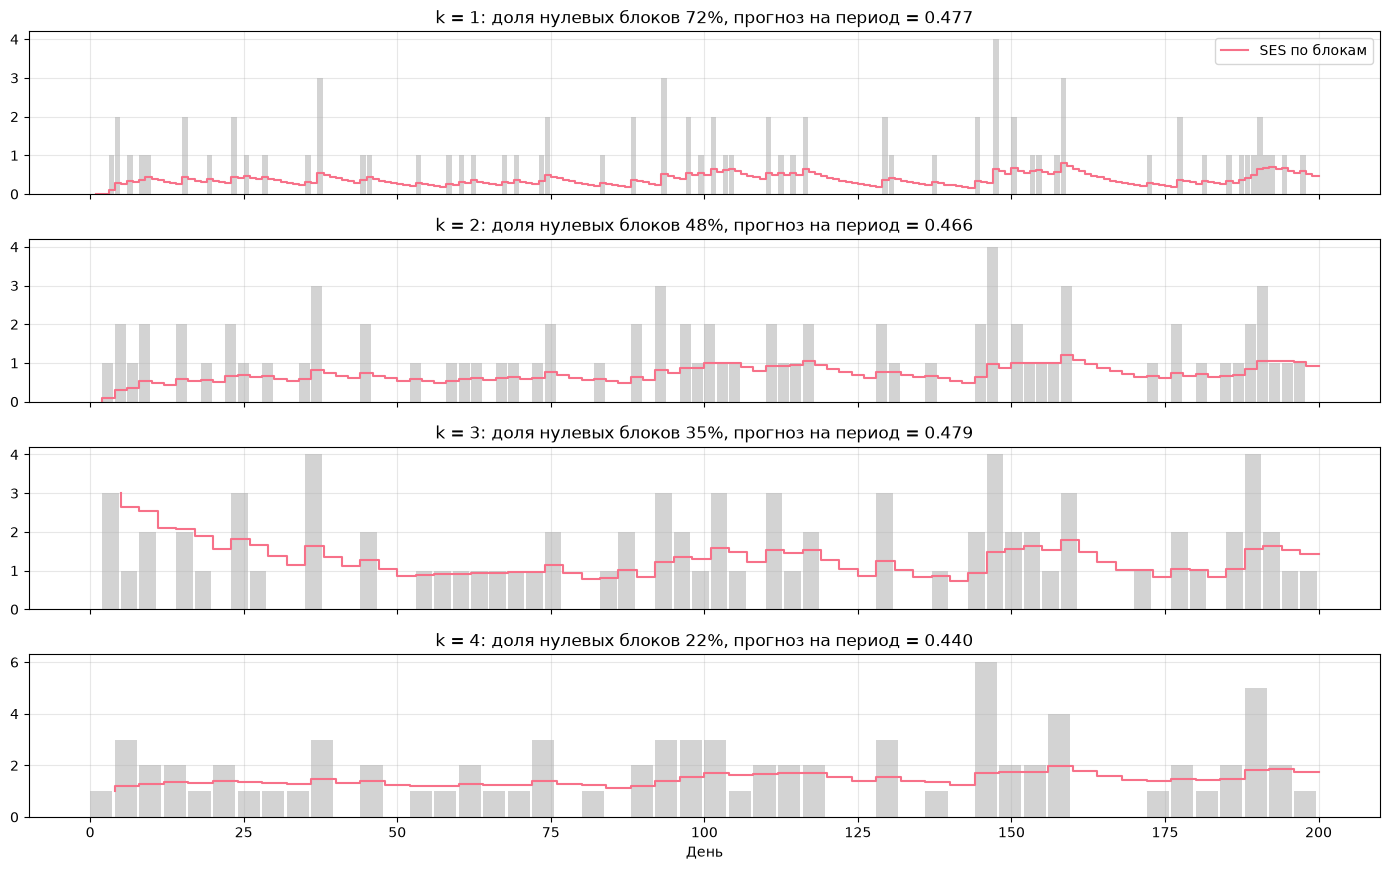

In [9]:
fig, axes = plt.subplots(K, 1, figsize=(14, 2.2 * K), sharex=True)
axes = np.atleast_1d(axes)

for ax, k in zip(axes, range(1, K + 1)):
    agg = aggregate(y_ex, k)
    _, alpha = ses_optimized(agg)
    x_pos = len(y_ex) - k * len(agg) + k * np.arange(len(agg))  # начало блока в днях
    ax.bar(x_pos, agg, width=k * 0.9, align='edge', color='lightgray')
    ax.step(x_pos + k, ses_path(agg, alpha), where='pre', color='C0', label='SES по блокам')
    share = (agg == 0).mean()
    ax.set_title(f'k = {k}: доля нулевых блоков {share:.0%}, прогноз на период = {per_level[k]:.3f}')
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel('День')
plt.tight_layout()
plt.show()

С ростом $k$ нулей становится меньше, ряд блоков — глаже. ADIDA берёт только верхний уровень,
IMAPA усредняет все.

## 5. Сравнение на M5 CA_1

Обучаем на всех 3049 товарах специализированные методы и бейзлайны из ноутбука 4 (Naive, SeasonalNaive,
HistoricAverage, SES), считаем метрики по классам спроса:
- **RMSSE** — RMSE, делённая на RMSE наивного прогноза на обучении: сравнима между товарами
  разного масштаба, < 1 — лучше наивного;
- **MAE** — в штуках в день; помним, что на прерывистых рядах MAE поощряет занижение (ноутбук 4);
- **Bias** = прогноз − факт: > 0 — перепрогноз, < 0 — недопрогноз.

Метрики считаются по каждому ряду и усредняются по товарам класса.

In [10]:
baselines = [
    Naive(),
    SeasonalNaive(season_length=7),
    HistoricAverage(),
    SimpleExponentialSmoothing(alpha=0.2),
]
intermittent_models = [
    CrostonClassic(),
    CrostonOptimized(),
    CrostonSBA(),
    TSB(alpha_d=0.1, alpha_p=0.1),
    ADIDA(),
    IMAPA(),
]

sf = StatsForecast(models=baselines + intermittent_models, freq='D', n_jobs=1)
forecast = sf.fit(train).predict(h=H)

In [11]:
results = evaluate_by_class(forecast, test, train, classes)
results['n_series'].loc['rmsse']

class
smooth           238
intermittent    2191
erratic           80
lumpy            540
all             3049
Name: n_series, dtype: int64

В каждой строке подсвечена лучшая модель для класса.

In [12]:
highlight_best(metric_table(results, 'rmsse'))

,Naive,SeasonalNaive,HistoricAverage,SES,CrostonClassic,CrostonOptimized,CrostonSBA,TSB,ADIDA,IMAPA
class,,,,,,,,,,
smooth,1.134,1.120,1.027,0.929,0.929,0.933,0.922,0.894,0.899,0.900
intermittent,1.077,1.135,0.924,0.886,0.900,0.906,0.897,0.864,0.865,0.864
erratic,0.989,0.928,0.859,0.789,0.784,0.822,0.775,0.744,0.762,0.775
lumpy,0.937,1.027,0.827,0.791,0.812,0.817,0.806,0.769,0.772,0.774
all,1.054,1.109,0.913,0.870,0.884,0.890,0.879,0.846,0.848,0.848


In [13]:
highlight_best(metric_table(results, 'mae'))

,Naive,SeasonalNaive,HistoricAverage,SES,CrostonClassic,CrostonOptimized,CrostonSBA,TSB,ADIDA,IMAPA
class,,,,,,,,,,
smooth,3.786,3.361,3.243,2.988,2.993,3.017,2.939,2.821,2.871,2.878
intermittent,0.920,0.887,0.815,0.780,0.826,0.836,0.815,0.762,0.770,0.771
erratic,4.412,4.011,4.350,3.479,3.558,3.754,3.485,3.255,3.402,3.453
lumpy,1.836,1.835,1.682,1.553,1.650,1.680,1.619,1.521,1.548,1.551
all,1.397,1.330,1.251,1.160,1.213,1.233,1.193,1.123,1.141,1.144


Для bias лучшая — с наименьшим смещением **по модулю**; знак смотрим в самой таблице.

In [14]:
highlight_best(metric_table(results, 'bias'), by_abs=True)

,Naive,SeasonalNaive,HistoricAverage,SES,CrostonClassic,CrostonOptimized,CrostonSBA,TSB,ADIDA,IMAPA
class,,,,,,,,,,
smooth,0.756,-0.009,-0.585,0.416,0.298,0.401,-0.002,0.152,0.256,0.264
intermittent,-0.041,-0.036,-0.208,0.005,0.036,0.085,-0.010,-0.015,-0.005,-0.000
erratic,0.704,0.245,1.193,0.476,0.598,0.911,0.332,0.201,0.472,0.528
lumpy,-0.087,-0.024,-0.101,0.023,0.109,0.200,0.019,0.012,0.061,0.068
all,0.033,-0.024,-0.182,0.053,0.084,0.152,0.005,0.009,0.040,0.046


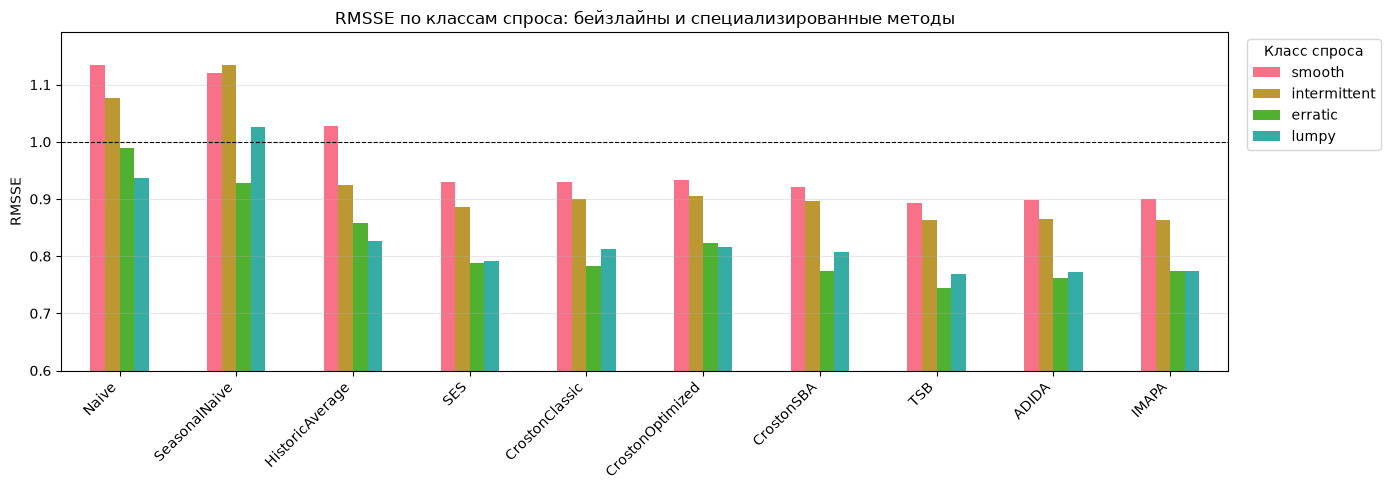

In [15]:
rmsse_table = metric_table(results, 'rmsse').drop(index='all')

ax = rmsse_table.T.plot(kind='bar', figsize=(14, 5))
ax.axhline(1, color='black', linestyle='--', linewidth=0.8)
ax.set_ylim(0.6, None)
ax.set_ylabel('RMSSE')
ax.set_title('RMSSE по классам спроса: бейзлайны и специализированные методы')
ax.legend(title='Класс спроса', bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(alpha=0.3, axis='y')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Наблюдения

- **TSB — лучший по RMSSE во всех четырёх классах** (0.846 в среднем), ADIDA и IMAPA почти вровень (0.848).
  Разница между лучшими методами — в третьем знаке; разрыв с Naive/SeasonalNaive (1.05–1.11) — в первом.
- **SES с α = 0.2 — сильный бейзлайн** (0.870): лучше CrostonClassic, CrostonOptimized и SBA по RMSSE.
  Специализированный метод сам по себе не гарантирует выигрыша.
- **CrostonOptimized хуже CrostonClassic** и сильнее всех завышает (bias +0.15 против +0.08):
  подбор α по MSE даёт α > 0.1, а смещение Croston растёт с α — ровно как в симуляции из раздела 2.
- **SBA убирает смещение:** bias +0.005 в среднем против +0.084 у CrostonClassic; на intermittent и lumpy
  SBA, TSB, ADIDA и IMAPA почти несмещённые.
- **HistoricAverage занижает** (bias −0.18): в тесте нулей меньше, чем в среднем по истории (53% против 64%),
  спрос вырос, а среднее за 5 лет этого не видит.
- **Erratic** — все методы завышают (bias до +1.2): редкие большие всплески тянут вверх оценку размера.
- Классы здесь считаются по обучению, поэтому их размеры чуть отличаются от ноутбука 4, где классы
  считались по всей истории.

## 6. Когда какой метод

| Метод | Что сглаживает | Параметры в `statsforecast` | Сильные стороны | Слабые стороны |
|-------|----------------|-----------------------------|-----------------|----------------|
| CrostonClassic | размер и интервал, в дни продаж | α = 0.1 | простой, классика | перепрогноз (Йенсен), застывает при простое |
| CrostonOptimized | то же | α ∈ [0.1, 0.3] по MSE, отдельно | подстраивается под ряд | больше α → больше смещение |
| CrostonSBA | то же × (1 − α/2) | 0.95 · CrostonClassic | убирает смещение Croston | застывает при простое |
| TSB | вероятность (каждый период) и размер | α_d, α_p вручную | реагирует на устаревание, без смещения | нужно выбирать α |
| ADIDA | сумму за k = round(ADI) периодов | SES, α ∈ [0.1, 0.3] | превращает прерывистый ряд в обычный | всё зависит от одного k |
| IMAPA | суммы за k = 1..K периодов | среднее по уровням, равные веса | ансамбль уровней, робастнее ADIDA | дороже, плоский прогноз |

Ни один из методов не знает про календарь: все прогнозы плоские по горизонту. Если важна недельная
сезонность, промо или известные нули — нужна модель с признаками (следующий ноутбук).

## Итог

- Croston сглаживает размер продажи и интервал между продажами отдельно; прогноз = $\hat z / \hat p$.
- Отношение даёт перепрогноз (неравенство Йенсена), растущий с α; SBA умножает на $(1 - \alpha/2)$ и убирает его.
- TSB сглаживает вероятность продажи каждый период → нет смещения и прогноз затухает у устаревших товаров.
- ADIDA агрегирует ряд блоками по round(ADI) периодов и прогнозирует SES; IMAPA усредняет прогнозы
  по всем уровням 1..K с равными весами.
- На M5 CA_1 лучший по RMSSE — TSB во всех классах, рядом ADIDA/IMAPA; SES — неожиданно сильный бейзлайн.
